# Homework 7 — Transcriptional bursting in a two-state gene model

**Module 2 · stochastic** · *Hao-Tian Jin* · 2026-11-02 · *Lecture 8 / Lab 5*

**Summary.** A promoter switching between OFF and ON makes mRNA arrive in bursts. With
$k_{\mathrm{on}}=0.2$, $k_{\mathrm{off}}=1$, $\beta=10$, $\gamma=0.1$ (all rates per min)
(2000 cells, $t_{\max}=500$ min) the SSA gives

| quantity | SSA | reference |
|---|---|---|
| mean $\langle m\rangle$ | 16.77 | 16.67 (mean equation) |
| Fano $=\operatorname{Var}/\langle m\rangle$ | 7.39 | 1 (Poisson) |

A negative binomial fits the data (AIC 14866 vs 23449 for Poisson), while a constitutive gene
with the same mean gives Fano 0.99. **Bursting is visible in the shape of the distribution,
not in its mean.** The notebook implements the SSA, compares the simulated distribution with Poisson and a
fitted negative binomial, and states which line of the algorithm does what.


# Model and notation

**Why an ON/OFF switch.** Transcriptional bursting arises from transcription-factor binding,
chromatin, enhancer--promoter contacts and transcriptional memory. The details differ, but
all of them act as a **slow two-state gate in front of a fast production process**, which is
the only feature the simulation below uses.

**Symbols.**

| symbol | meaning |
|---|---|
| $s\in\{0,1\}$ | promoter state: $1=$ ON, $0=$ OFF |
| $m$ | mRNA copy number in one cell |
| $k_{\mathrm{on}}$ | OFF $\to$ ON rate (1/min) |
| $k_{\mathrm{off}}$ | ON $\to$ OFF rate (1/min) |
| $\beta$ | transcription rate while ON (mRNA/min) |
| $\gamma$ | degradation rate per mRNA (1/min) |
| $a_j$ | propensity of reaction $j$ (1/min) |

**Reactions and propensities.** State $(s,m)$:

$$
\begin{aligned}
\text{activation:}    && \mathrm{DNA_{OFF}} &\xrightarrow{k_{\mathrm{on}}} \mathrm{DNA_{ON}},
&& a_1 &= k_{\mathrm{on}}(1-s),\\
\text{inactivation:}  && \mathrm{DNA_{ON}} &\xrightarrow{k_{\mathrm{off}}} \mathrm{DNA_{OFF}},
&& a_2 &= k_{\mathrm{off}}s,\\
\text{transcription:} && \mathrm{DNA_{ON}} &\xrightarrow{\beta} \mathrm{DNA_{ON}}+m,
&& a_3 &= \beta s,\\
\text{degradation:}   && m &\xrightarrow{\gamma} \varnothing,
&& a_4 &= \gamma m.
\end{aligned}
$$

**Mean.** $\dot{\langle s\rangle}=k_{\mathrm{on}}(1-\langle s\rangle)-k_{\mathrm{off}}\langle s\rangle$
and $\dot{\langle m\rangle}=\beta\langle s\rangle-\gamma\langle m\rangle$, so at stationarity
$\langle s\rangle=k_{\mathrm{on}}/(k_{\mathrm{on}}+k_{\mathrm{off}})$ and

$$
\langle m\rangle=\frac{\beta k_{\mathrm{on}}}{\gamma(k_{\mathrm{on}}+k_{\mathrm{off}})}=16.67 .
$$

An ON episode lasts $\approx 1/k_{\mathrm{off}}$ and makes $\approx\beta/k_{\mathrm{off}}=10$ mRNAs;
bursts arrive at rate $k_{\mathrm{on}}$.


# Gillespie SSA

At each step $a_0=\sum_j a_j$. The waiting time is exponential, $\tau=-\ln(u_1)/a_0$; the
reaction is the first $j$ with $\sum_{i\le j}a_i>u_2a_0$ ($u_1,u_2\sim U(0,1)$). This is exact
because exponential waits are memoryless and the propensities are constant between events.
The state vector now carries $s$ as well as $m$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize
from scipy.special import gammaln

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "legend.frameon": False,
})

# all rates in min^-1
K_ON = 0.2
K_OFF = 1.0
BETA = 10.0
GAMMA = 0.1

T_MAX = 500.0      # 50 mRNA lifetimes: the initial condition is forgotten
N_CELLS = 2000
SEED = 20261030

In [2]:
def simulate_one_cell(k_on, k_off, beta, gamma, t_max, rng, m0=0, s0=0):
    """Return the reaction-by-reaction trajectory of a single cell."""
    t = 0.0
    s = s0
    m = m0
    times = [t]
    promoters = [s]
    mrna = [m]

    while t < t_max:
        a_activation = k_on * (1 - s)
        a_inactivation = k_off * s
        a_transcription = beta * s
        a_degradation = gamma * m
        a_total = a_activation + a_inactivation + a_transcription + a_degradation

        if a_total <= 0:
            break

        t = t + (-np.log(rng.random()) / a_total)
        if t >= t_max:
            break

        threshold = rng.random() * a_total
        if threshold < a_activation:
            s = 1
        elif threshold < a_activation + a_inactivation:
            s = 0
        elif threshold < a_activation + a_inactivation + a_transcription:
            m = m + 1
        else:
            m = m - 1

        times.append(t)
        promoters.append(s)
        mrna.append(m)

    return np.array(times), np.array(promoters), np.array(mrna)

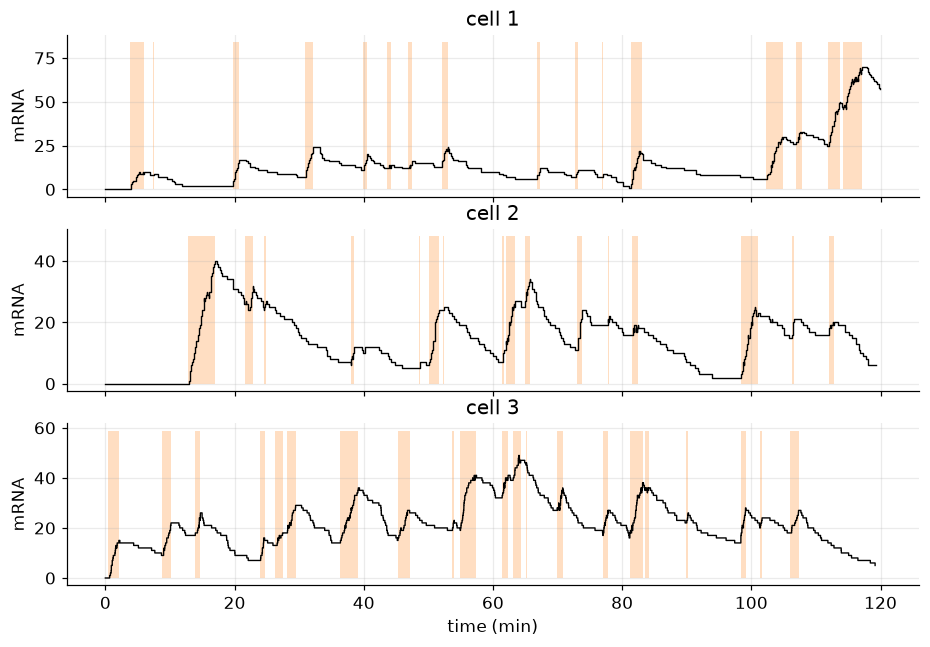

In [3]:
rng = np.random.default_rng(SEED)

fig, axes = plt.subplots(3, 1, figsize=(10, 6.5), sharex=True)
for axis, cell_number in zip(axes, range(3)):
    times, promoters, counts = simulate_one_cell(K_ON, K_OFF, BETA, GAMMA, 120.0, rng)
    axis.step(times, counts, where="post", color="black", lw=0.9)
    axis.fill_between(times, 0, counts.max() * 1.2, where=promoters == 1,
                      step="post", color="tab:orange", alpha=0.25, lw=0)
    axis.set_ylabel("mRNA")
    axis.set_title(f"cell {cell_number + 1}")
axes[-1].set_xlabel("time (min)")
plt.show()

# Steady-state distribution

The ensemble version is the same loop without recording: storing every event would make time
and memory grow with $t_{\max}$. Keeping only the final count after 50 mRNA lifetimes samples
the stationary distribution (ergodicity).

In [4]:
def final_mrna_counts(k_on, k_off, beta, gamma, t_max, n_cells, rng):
    """Same SSA loop, but only the final count of each cell is kept."""
    counts = np.empty(n_cells, dtype=int)
    for cell in range(n_cells):
        t = 0.0
        s = 0
        m = 0
        while True:
            a_activation = k_on * (1 - s)
            a_inactivation = k_off * s
            a_transcription = beta * s
            a_degradation = gamma * m
            a_total = a_activation + a_inactivation + a_transcription + a_degradation

            if a_total <= 0:
                break

            t = t + (-np.log(rng.random()) / a_total)
            if t >= t_max:
                break

            threshold = rng.random() * a_total
            if threshold < a_activation:
                s = 1
            elif threshold < a_activation + a_inactivation:
                s = 0
            elif threshold < a_activation + a_inactivation + a_transcription:
                m = m + 1
            else:
                m = m - 1
        counts[cell] = m
    return counts


rng = np.random.default_rng(SEED + 1)
counts = final_mrna_counts(K_ON, K_OFF, BETA, GAMMA, T_MAX, N_CELLS, rng)

sample_mean = counts.mean()
sample_var = counts.var(ddof=1)
sample_fano = sample_var / sample_mean

reference_mean = BETA * K_ON / (GAMMA * (K_ON + K_OFF))

print(f"{'quantity':<10}{'SSA':>10}{'reference':>10}")
print(f"{'mean':<10}{sample_mean:>10.2f}{reference_mean:>10.2f}")
print(f"{'variance':<10}{sample_var:>10.2f}{reference_mean:>10.2f}")
print(f"{'Fano':<10}{sample_fano:>10.2f}{1.0:>10.2f}")

quantity         SSA reference
mean           16.77     16.67
variance      123.89     16.67
Fano            7.39      1.00


## Negative-binomial fit

The burst model predicts a negative binomial,
$P(k)=\binom{k+n-1}{k}p^n(1-p)^k$ with mean $n(1-p)/p$, variance $n(1-p)/p^2$ and $F=1/p$.
$(n,p)$ are fitted by maximum likelihood; the optimiser uses $\log n$ and $\operatorname{logit}p$
so the constraints $n>0$, $0<p<1$ hold automatically, and the method-of-moments estimate is
the starting point. Poisson (one parameter) and negative binomial (two) are compared by AIC.

In [5]:
def negative_binomial_log_pmf(counts, n, p):
    counts = np.asarray(counts)
    log_coefficient = gammaln(counts + n) - gammaln(n) - gammaln(counts + 1)
    return log_coefficient + n * np.log(p) + counts * np.log(1 - p)


def negative_binomial_negative_log_likelihood(params, counts):
    n = np.exp(params[0])
    p = 1.0 / (1.0 + np.exp(-params[1]))
    return -negative_binomial_log_pmf(counts, n, p).sum()


def fit_negative_binomial(counts):
    sample_mean = counts.mean()
    sample_var = counts.var(ddof=1)
    p_guess = sample_mean / sample_var
    n_guess = sample_mean * p_guess / (1 - p_guess)
    start = np.array([np.log(n_guess), np.log(p_guess / (1 - p_guess))])
    result = minimize(negative_binomial_negative_log_likelihood, start, args=(counts,),
                      method="Nelder-Mead",
                      options={"xatol": 1e-10, "fatol": 1e-10, "maxiter": 20000})
    return np.exp(result.x[0]), 1.0 / (1.0 + np.exp(-result.x[1]))


n_hat, p_hat = fit_negative_binomial(counts)
poisson_log_likelihood = stats.poisson.logpmf(counts, sample_mean).sum()
nb_log_likelihood = negative_binomial_log_pmf(counts, n_hat, p_hat).sum()

print(f"negative binomial: n = {n_hat:.3f}, p = {p_hat:.4f}, "
      f"burst size b = (1-p)/p = {(1 - p_hat) / p_hat:.2f} (SSA F - 1 = {sample_fano - 1:.2f})")
print(f"AIC: Poisson {2 * 1 - 2 * poisson_log_likelihood:.1f}, "
      f"negative binomial {2 * 2 - 2 * nb_log_likelihood:.1f}")

negative binomial: n = 2.374, p = 0.1240, burst size b = (1-p)/p = 7.06 (SSA F - 1 = 6.39)
AIC: Poisson 23449.4, negative binomial 14866.5


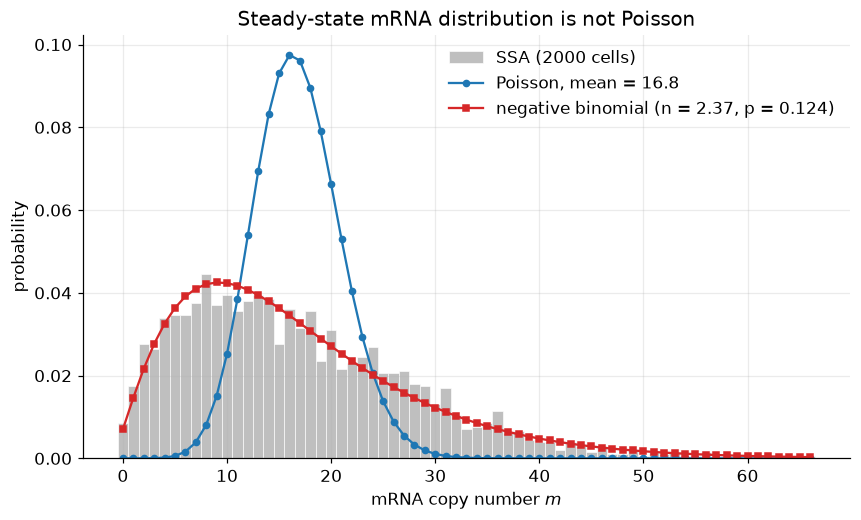

In [6]:
k_max = int(np.quantile(counts, 0.999))
k_grid = np.arange(0, k_max + 1)
bin_edges = np.arange(-0.5, k_max + 1.5, 1.0)

fig, axis = plt.subplots(figsize=(9, 5))
axis.hist(counts, bins=bin_edges, density=True, color="0.75",
          edgecolor="white", linewidth=0.4, label="SSA (2000 cells)")
axis.plot(k_grid, stats.poisson.pmf(k_grid, sample_mean), "o-", ms=4,
          color="tab:blue", label=f"Poisson, mean = {sample_mean:.1f}")
axis.plot(k_grid, stats.nbinom.pmf(k_grid, n_hat, p_hat), "s-", ms=4,
          color="tab:red", label=f"negative binomial (n = {n_hat:.2f}, p = {p_hat:.3f})")
axis.set_xlabel("mRNA copy number $m$")
axis.set_ylabel("probability")
axis.set_title("Steady-state mRNA distribution is not Poisson")
axis.legend()
plt.show()

# Control: constitutive expression with the same mean

Same mean, no promoter: $\beta_{\mathrm{const}}=\gamma\langle m\rangle$, two-reaction birth–death
SSA. Its stationary law is Poisson, so $F=1$; any difference from the bursty case is due to
promoter switching alone.

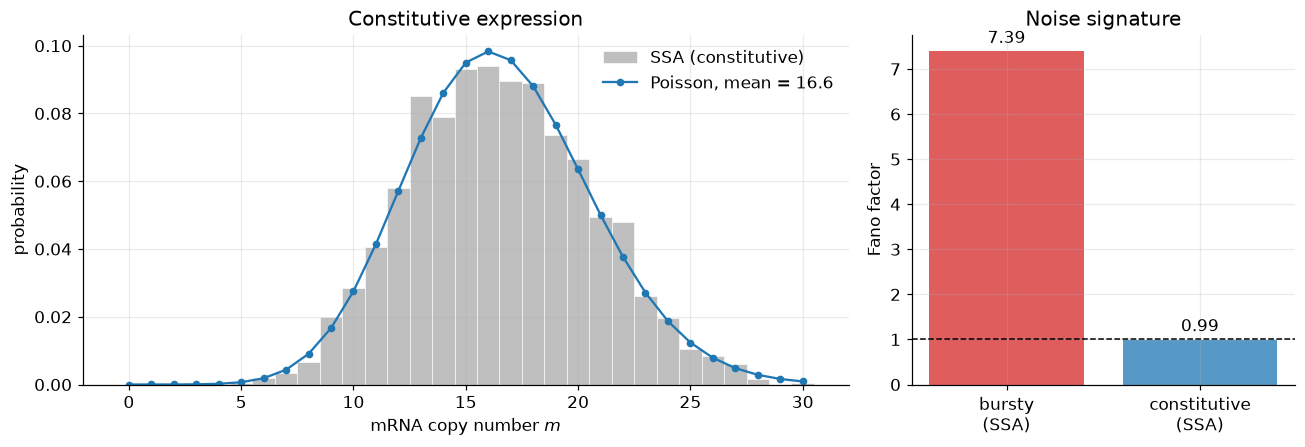

In [7]:
def final_mrna_counts_constitutive(beta, gamma, t_max, n_cells, rng):
    counts = np.empty(n_cells, dtype=int)
    for cell in range(n_cells):
        t = 0.0
        m = 0
        while True:
            a_birth = beta
            a_death = gamma * m
            a_total = a_birth + a_death
            t = t + (-np.log(rng.random()) / a_total)
            if t >= t_max:
                break
            if rng.random() * a_total < a_birth:
                m = m + 1
            else:
                m = m - 1
        counts[cell] = m
    return counts


rng = np.random.default_rng(SEED + 2)
counts_constitutive = final_mrna_counts_constitutive(
    GAMMA * reference_mean, GAMMA, T_MAX, N_CELLS, rng)

k_max_constitutive = int(np.quantile(counts_constitutive, 0.999))
k_grid_constitutive = np.arange(0, k_max_constitutive + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [2, 1]})
axes[0].hist(counts_constitutive, bins=np.arange(-0.5, k_max_constitutive + 1.5, 1.0),
             density=True, color="0.75", edgecolor="white", linewidth=0.4,
             label="SSA (constitutive)")
axes[0].plot(k_grid_constitutive,
             stats.poisson.pmf(k_grid_constitutive, counts_constitutive.mean()), "o-", ms=4,
             color="tab:blue", label=f"Poisson, mean = {counts_constitutive.mean():.1f}")
axes[0].set_xlabel("mRNA copy number $m$")
axes[0].set_ylabel("probability")
axes[0].set_title("Constitutive expression")
axes[0].legend()

constitutive_fano = counts_constitutive.var(ddof=1) / counts_constitutive.mean()
values = [sample_fano, constitutive_fano]
axes[1].bar(["bursty\n(SSA)", "constitutive\n(SSA)"], values,
            color=["tab:red", "tab:blue"], alpha=0.75)
axes[1].axhline(1.0, color="black", ls="--", lw=1)
axes[1].set_ylabel("Fano factor")
axes[1].set_title("Noise signature")
for position, value in enumerate(values):
    axes[1].text(position, value + 0.1, f"{value:.2f}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

# Discussion

1. **The mean is not the signature.** Bursty and constitutive genes have the same
   $\langle m\rangle\approx 16.7$, but $\operatorname{Var}(m)\approx 7\langle m\rangle$ versus
   $\langle m\rangle$. Poisson is rejected by the likelihood; the negative binomial reproduces
   the long right tail.
2. **The fit parameters carry the mechanism.** The fitted $n=2.37$ matches the burst frequency
   $k_{\mathrm{on}}/\gamma=2$, and $b=(1-p)/p=7.1$ is close to the observed excess noise
   $F-1\approx6.4$; it is below $\beta/k_{\mathrm{off}}=10$ because $k_{\mathrm{off}}/\gamma=10$ is not
   deep in the burst limit.
3. **Bursting is a time-scale phenomenon.** Slow switching gives a broad/bimodal law, the burst
   regime a negative binomial, fast switching a Poisson. The exact negative-binomial law is an
   approximation (the exact stationary law is Beta–Poisson), which is invisible at 2000 cells
   but not at $10^5$.
4. **Caveats.** Intrinsic noise only (no cell-to-cell parameter variation), one sampling time,
   exactly two promoter states.
